### Build a Basic Chatbot with Langgraph (Graph API)

Components of Langgraph
1. Edge
2. Nodes
3. State

- Edge -> Transfers the o/p & Direction of Workflow
- Node -> Contains the Functionality with i/p and o/p
- State -> The variables that can be accessible to any node

Usecase - You tube Videos - Create a blog out of a video 
Workflow : 
1. Youtube Video -> Transcript 
2. Transcript -> Title
3. Title, Transcript -> Content


Two ways to solve the use-case
1. Graph API
2. Functional API


1. Start -> YouTube Video Transcript (Node Implementation) (Langchain YT Loader)  -> Transcript
2. Transcript -> Generate Title (Node) -> Title
3. Title, Transcript -> Generate Content (Node) -> Content of the Blog -> End

In [1]:
import os
from typing_extensions import TypedDict, Annotated
from langgraph.graph import StateGraph,  START, END
from langgraph.graph.message import add_messages # Reducer  - to add messages to the graph

In [2]:
class State(TypedDict):
    """
    The state of the chatbot.
    Messages have the type 'list'. The 'add_messages' function in the annotation defines how this state key
    should be update. In this case, it appends the new messages to the existing list of messages rather than replacing it.
    """
    messages: Annotated[list, add_messages]


In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-4.1")
llm = model
model

response = model.invoke("Hello, how are you?")
print(response.content)

Hello! I'm just a computer program, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?


In [4]:
# Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}


In [5]:
graph_builder = StateGraph(State)

# Add nodes to the graph
graph_builder.add_node("llmchatbot", chatbot)

# Add edges to the graph
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

# Compile the graph
graph = graph_builder.compile()


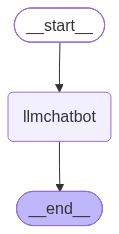

In [6]:
# Visualize the graph
from IPython.display import display,Image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed. Please ensure you have graphviz installed and configured correctly.")
    print(f"Error: {e}")

In [7]:
response = graph.invoke({"messages":["Hello, how are you?"]})
response["messages"]

[HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='66ecff5b-9fd0-40a2-ac56-79df1d50a0e6'),
 AIMessage(content="Hello! I'm just a language model, but I'm here and ready to help you. How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 13, 'total_tokens': 37, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_8a456ba4f1', 'id': 'chatcmpl-EbRWVcC8Rb0RLznzID9nm1LbC9ykP', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15ed9-03ae-7728-b6cb-5554051e9651-0', tool_calls=[], invalid_tool_calls=[]

In [8]:
response = graph.invoke({"messages":["I Love you"]})
print(response["messages"])
print(response["messages"][-1].content)

[HumanMessage(content='I Love you', additional_kwargs={}, response_metadata={}, id='c247d36d-c4fb-4353-b811-d2638a4321af'), AIMessage(content="Aww, that's sweet! ❤️ I'm here for you—how can I help today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 10, 'total_tokens': 28, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_87b97c2d72', 'id': 'chatcmpl-EbRWWvT6PyZNtA8VLg5xHcbb11lNy', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15ed9-0736-757b-858c-2d753c63f0af-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_t

In [9]:
for event in graph.stream({"messages":["I Love you"]}):
    print(event)

{'llmchatbot': {'messages': [AIMessage(content="Aww, thank you! 😊 That’s so sweet of you to say. I'm here for you—how can I make your day better?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 10, 'total_tokens': 39, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_87b97c2d72', 'id': 'chatcmpl-EbRWXTjATy6uO3g1Q8AnVAnZLoXzK', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15ed9-0cc8-7073-9a01-a031d6926112-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 29, 'total_tokens': 39, 'input_token_details': {'a

In [10]:
for event in graph.stream({"messages":["I Love you"]}):
    for value in event.values():
        print(value["messages"][-1].content )

Aww, thank you! 😊 I'm here for you whenever you need me. How can I help you today?


### Chatbot with Tool


In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model
from langchain_tavily import TavilySearch

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

tool = TavilySearch(max_results=3, search_type="web", search_mode="realtime")
tool.invoke("What is langgraph?")


{'query': 'What is langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how

In [14]:
# Custom Function

def multiply(a: int, b: int) -> int:
    """ Multiplies two integers and returns the result. """
    return a * b

tools = [tool, multiply]

from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-4.1")
llm = model

llm_with_tool= llm.bind_tools(tools)

In [ ]:
# Stategraph with tools
from langgraph.graph import StateGraph,  START, END
from langgraph.graph.message import add_messages # Reducer  - to add messages to the graph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# Node defination

# Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", llm_with_tool)

# Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_edge("tool_calling_llm", END, condition=tools_condition)
